<a href="https://colab.research.google.com/github/yotoqxonacom-hub/computer_vision/blob/main/pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch

In [3]:
print(torch.__version__)

2.11.0+cu130


In [4]:
print('CUDA available:', torch.cuda.is_available)

CUDA available: <function is_available at 0x7ca1d8005580>


In [10]:
scalar = torch.tensor(5) #0D
print('scalar:', scalar)
print('shape:', scalar.shape)

scalar: tensor(5)
shape: torch.Size([])


In [19]:
vector = torch.tensor([1,2,3]) #1D
print('vector:', vector)
print('shape:', vector.shape)
print('number of dimantion:', vector.ndim)
print('Size:', vector.size())

vector: tensor([1, 2, 3])
shape: torch.Size([3])
number of dimantion: 1
Size: torch.Size([3])


In [22]:
MATRIX = torch.tensor([[2,4,7],[1,3,6]])  #2D
print('MATRIX:', MATRIX)
print('shape:', MATRIX.shape)
print('number of dimantion:', MATRIX.ndim)
print('Size:', MATRIX.size())

MATRIX: tensor([[2, 4, 7],
        [1, 3, 6]])
shape: torch.Size([2, 3])
number of dimantion: 2
Size: torch.Size([2, 3])


In [23]:
tensor3d = torch.stack([MATRIX,MATRIX +10]) #3
print("tensor3d:", tensor3d)
print('shape:', tensor3d.shape) # [2,2,3] | 2 matrices => stack, | 2 row in each matrix  | (haight, width) 3 c in m
print('number of dimantion:', tensor3d.ndim)
print('Size:', tensor3d.size())

tensor3d: tensor([[[ 2,  4,  7],
         [ 1,  3,  6]],

        [[12, 14, 17],
         [11, 13, 16]]])
shape: torch.Size([2, 2, 3])
number of dimantion: 3
Size: torch.Size([2, 2, 3])


In [28]:
random_numbers = torch.rand(2, 3)  # 0 ~ 1
print('Random Numbers:', random_numbers)
print('data type: ', random_numbers.dtype)
print('device of random numbers: ', random_numbers.device)

Random Numbers: tensor([[0.4703, 0.9235, 0.5566],
        [0.3835, 0.7126, 0.5465]])
data type:  torch.float32
device of random numbers:  cpu


In [25]:
print("Zeros:", torch.zeros(3,3))

Zeros: tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


In [26]:
print('ones:', torch.ones(2,4))

ones: tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]])


In [31]:
x = torch.tensor([[1, 2],
                  [3, 4]])

y = torch.tensor([[5, 6],
                  [7, 8]])

# Element-wise addition
print('Addition:', x + y)
print("================")

# Element-wise multiplication
print('Multiplication:', x * y)
print("================")

# Matrix multiplication
#print('Matrix @ multiplication:', x @ y)
print('Matrix @ multiplication:', torch.matmul(x,y))

# x
# [[1, 2],
#  [3, 4]]

# y
# [[5, 6],
#  [7, 8]]

Addition: tensor([[ 6,  8],
        [10, 12]])
Multiplication: tensor([[ 5, 12],
        [21, 32]])
Matrix @ multiplication: tensor([[19, 22],
        [43, 50]])


# [1, 2] · [5, 7] = 1*5 + 2*7 = 5 + 14 = 19

# [1, 2] · [6, 8] = 1*6 + 2*8 = 6 + 16 = 22

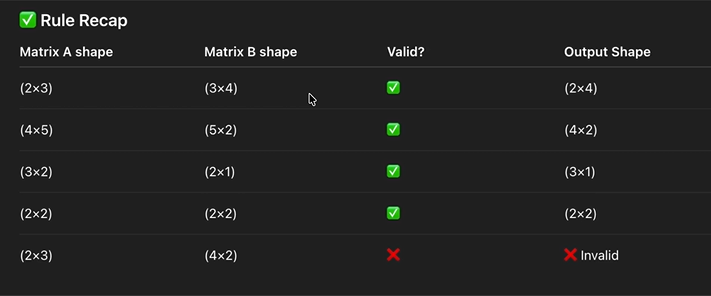

In [32]:
# Import PyTorch and matplotlib
import torch
from torch import nn  # nn contains all of PyTorch's building blocks for neural networks
import matplotlib.pyplot as plt

# Check PyTorch version
torch.__version__

'2.11.0+cu130'

In [33]:
# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [34]:
# Create weight and bias
weight = 0.7
bias = 0.3

# Create range values
start = 0
end = 1
step = 0.02

# Create X and y (features and labels)
X = torch.arange(start, end, step).unsqueeze(dim=1)  # without unsqueeze, errors will happen later on (shapes within linear layers)
y = weight * X + bias

# Split data
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

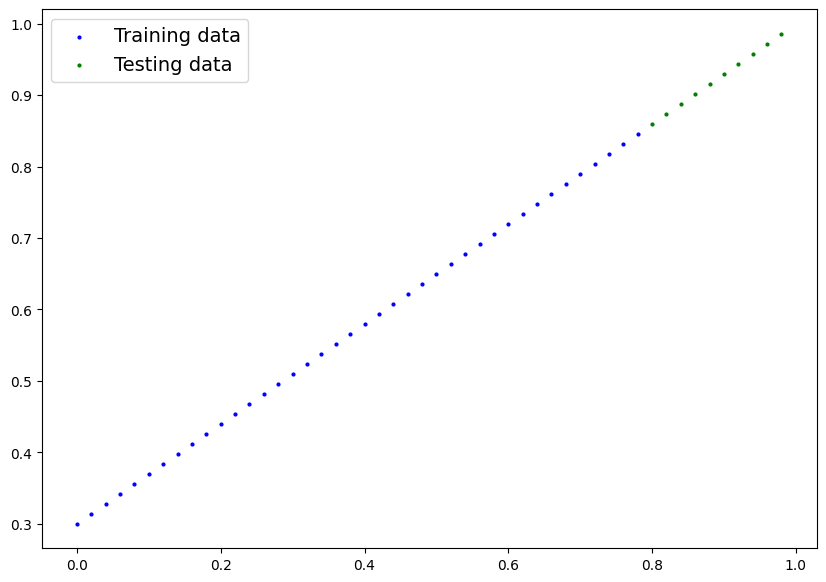

In [35]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):

    plt.figure(figsize=(10, 7))

    # Plot training data in blue
    plt.scatter(train_data, train_labels, c='b', s=4, label='Training data')

    # Plot test data in green
    plt.scatter(test_data, test_labels, c='g', s=4, label='Testing data')

    if predictions is not None:
        plt.scatter(test_data, predictions, c='r', s=4, label='Predictions')

    plt.legend(prop={'size': 14})

plot_predictions()

In [37]:
# Subclass nn.Module to make our model
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()

        # Use nn.Linear() for creating the model parameters
        self.linear_layer = nn.Linear(in_features=1,
                                      out_features=1) #Linear => y =wx+b

    # Define the forward computation (input data x flows through nn.Linear())
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)

# Set the manual seed when creating the model
# (this isn't always needed but is used for demonstrative purposes, try commenting it out)
torch.manual_seed(42)

model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()

(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [39]:
# Create loss function
loss_fn = nn.L1Loss()

# Create optimizer
optimizer = torch.optim.SGD(
    params=model_1.parameters(),  # optimize newly created model's parameters

    lr=0.01)


Text(0.5, 1.0, 'Predictions before training (red = random guesses)')

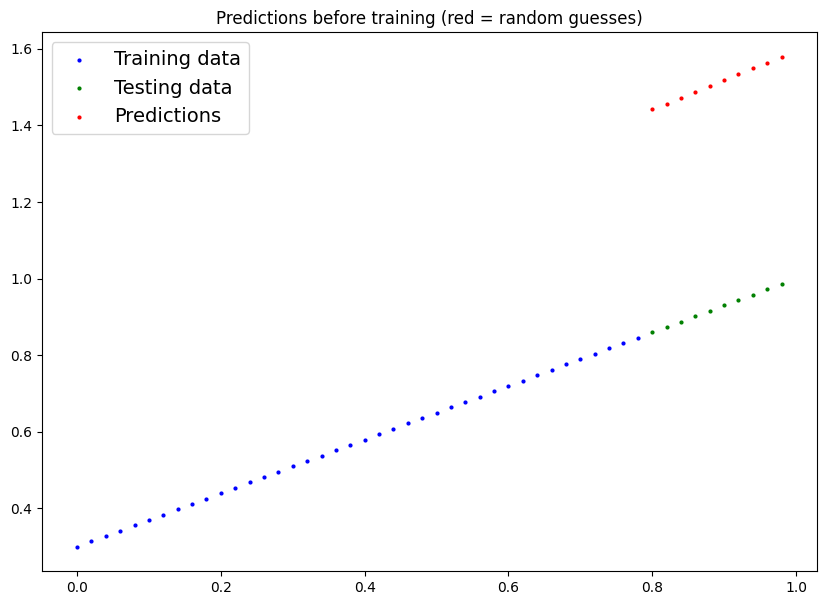

In [40]:
# See model's untrained predictions (on test set)
model_1.eval()

with torch.inference_mode():
    y_preds_early = model_1(X_test)

plot_predictions(predictions=y_preds_early)
plt.title("Predictions before training (red = random guesses)")

In [44]:
# Epochlar soni
epochs = 1000

# Modelni va ma'lumotlarni bir xil qurilmaga (device) o'tkazish
model_1.to(device)

X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

for epoch in range(epochs):
    ### Training
    model_1.train()

    # 1. Forward pass
    y_pred = model_1(X_train)

    # 2. Loss hisoblash
    loss = loss_fn(y_pred, y_train)

    # 3. Gradientlarni nolga tushirish
    optimizer.zero_grad()

    # 4. Backpropagation
    loss.backward()

    # 5. Optimizer qadami
    optimizer.step()

    ### Testing
    model_1.eval()
    with torch.inference_mode():
        # 1. Forward pass
        test_pred = model_1(X_test)

        # 2. Test loss
        test_loss = loss_fn(test_pred, y_test)

    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Train loss: {loss.item():.5f} | Test loss: {test_loss.item():.5f}")

Epoch: 0 | Train loss: 0.55518 | Test loss: 0.57398
Epoch: 100 | Train loss: 0.00622 | Test loss: 0.01409
Epoch: 200 | Train loss: 0.00126 | Test loss: 0.01380
Epoch: 300 | Train loss: 0.00126 | Test loss: 0.01380
Epoch: 400 | Train loss: 0.00126 | Test loss: 0.01380
Epoch: 500 | Train loss: 0.00126 | Test loss: 0.01380
Epoch: 600 | Train loss: 0.00126 | Test loss: 0.01380
Epoch: 700 | Train loss: 0.00126 | Test loss: 0.01380
Epoch: 800 | Train loss: 0.00126 | Test loss: 0.01380
Epoch: 900 | Train loss: 0.00126 | Test loss: 0.01380


In [45]:
# Turn model into evaluation mode
model_1.eval()

# Make predictions on the test data
with torch.inference_mode():
    y_preds = model_1(X_test)

y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]], device='cuda:0')

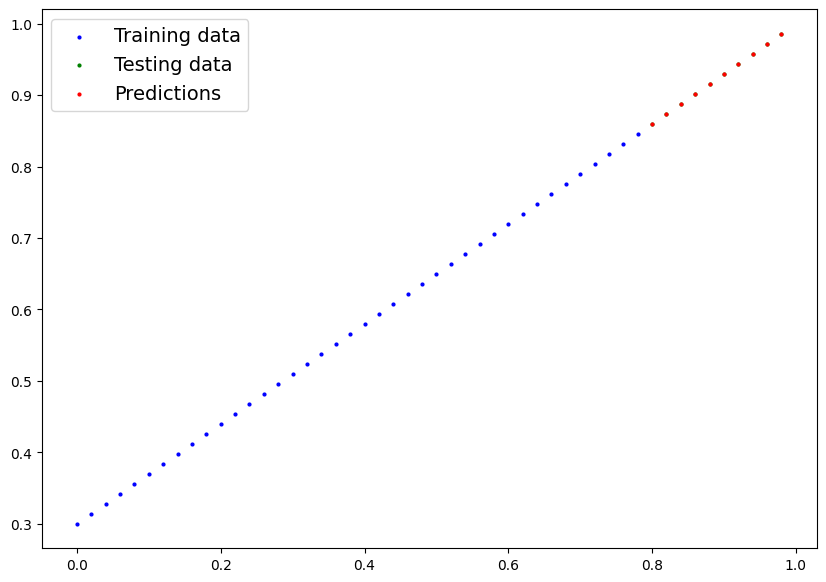

In [47]:
# Ma'lumotni CPU'ga o'tkazib, grafik chizish
plot_predictions(predictions=y_preds.cpu())

In [49]:
torch.save(model_1.state_dict(), 'trained_model.pth')

In [50]:
loaded_model = LinearRegressionModelV2()

loaded_model.load_state_dict(
    torch.load('/content/trained_model.pth')
)

loaded_model.eval()

LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)